# 07 - Inventory-policy simulation and final evaluation

This notebook answers the central project question using the reserved final period, `d_1914` through `d_1941`.

Two transparent periodic-review policies are compared:

- **Probabilistic buffer:** each series receives its own empirical protection-period error quantile.
- **Fixed buffer:** every series receives the same additive buffer, chosen to match the probabilistic policy's average buffer at the same target quantile.

Both policies use the same selected point forecast, demand path, 7-day review interval, 7-day lead time, and starting rules. Matching the average buffer isolates whether allocating uncertainty by series improves the service-inventory tradeoff.

No model or policy choice is changed after final-test sales are loaded.

## 1. Imports and fixed policy assumptions

The policy rules and statistical inputs are loaded before final-test outcomes. The simulation uses lost sales: demand that cannot be filled immediately is recorded as unmet and is not backordered.

In [1]:
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures" / "inventory_simulation"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_END = 1885
VALIDATION_END = 1913
TEST_START = 1914
TEST_END = 1941
LEAD_TIME_DAYS = 7
REVIEW_PERIOD_DAYS = 7
PROTECTION_PERIOD_DAYS = LEAD_TIME_DAYS + REVIEW_PERIOD_DAYS
TARGET_QUANTILES = [0.80, 0.90, 0.95]
BOOTSTRAP_REPETITIONS = 5000
RANDOM_SEED = 500

rng = np.random.default_rng(RANDOM_SEED)
print(f"Final test: d_{TEST_START} to d_{TEST_END}")
print(f"Periodic review: R={REVIEW_PERIOD_DAYS}, L={LEAD_TIME_DAYS}, protection={PROTECTION_PERIOD_DAYS} days")

Final test: d_1914 to d_1941
Periodic review: R=7, L=7, protection=14 days


## 2. Load policy inputs and define matched buffers

The probabilistic protection buffers come from training-only 14-day forecast errors. For each target, the fixed policy uses their mean. The policies therefore receive the same average buffer across the 12 selected series before integer rounding.

In [2]:
metadata = pd.read_csv(PROCESSED_DATA_DIR / "selected_series_metadata.csv")
development = pd.read_csv(
    PROCESSED_DATA_DIR / "selected_series_development.csv",
    parse_dates=["date"],
)
model_selection = pd.read_csv(PROCESSED_DATA_DIR / "forecast_model_selection.csv")
seven_day_safety = pd.read_csv(PROCESSED_DATA_DIR / "safety_stock_levels.csv")
protection_quantiles = pd.read_csv(PROCESSED_DATA_DIR / "protection_period_error_quantiles.csv")

series_order = metadata["series_key"].tolist()
assert development["day_number"].max() == VALIDATION_END
assert len(protection_quantiles) == 12

fixed_protection_buffers = {
    target: protection_quantiles[f"buffer_q{int(target * 100)}"].mean()
    for target in TARGET_QUANTILES
}
fixed_initial_buffers = {
    target: seven_day_safety.loc[
        seven_day_safety["target_quantile"].round(2) == target,
        "safety_stock",
    ].mean()
    for target in TARGET_QUANTILES
}

policy_definition = pd.DataFrame(
    {
        "target_quantile": TARGET_QUANTILES,
        "fixed_initial_7_day_buffer": [fixed_initial_buffers[target] for target in TARGET_QUANTILES],
        "fixed_14_day_protection_buffer": [fixed_protection_buffers[target] for target in TARGET_QUANTILES],
        "probabilistic_mean_14_day_buffer": [
            protection_quantiles[f"buffer_q{int(target * 100)}"].mean()
            for target in TARGET_QUANTILES
        ],
    }
)
display(policy_definition.round(2))

,target_quantile,fixed_initial_7_day_buffer,fixed_14_day_protection_buffer,probabilistic_mean_14_day_buffer
0,0.80,10.61,18.71,18.71
1,0.90,16.95,34.17,34.17
2,0.95,22.68,42.81,42.81


## 3. Forecasting and periodic-review mechanics

At the start of the final period, on-hand inventory covers the first seven-day lead time. At every weekly review:

1. any scheduled order arrives;
2. the selected baseline forecasts the next 14-day protection period;
3. the inventory position is on-hand inventory plus outstanding orders;
4. an order raises that position to the policy's order-up-to level; and
5. the order arrives after seven days.

Demand is then fulfilled daily from on-hand inventory. This keeps the operational rules identical across policies.

In [3]:
def baseline_forecast(history, model, horizon):
    if model == "last_value":
        forecast = np.repeat(history[-1], horizon)
    elif model == "seasonal_naive_7":
        forecast = np.resize(history[-7:], horizon)
    elif model == "mean_28":
        forecast = np.repeat(history[-28:].mean(), horizon)
    else:
        raise ValueError(f"Unknown model: {model}")
    return np.maximum(forecast.astype("float64"), 0.0)


development_wide = (
    development.pivot(index="series_key", columns="day_number", values="sales")
    .reindex(index=series_order, columns=range(1, VALIDATION_END + 1))
)
assert development_wide.notna().all().all()

policy_buffers = []
for series_key in series_order:
    for target in TARGET_QUANTILES:
        suffix = int(target * 100)
        probabilistic_protection = protection_quantiles.loc[
            protection_quantiles["series_key"] == series_key,
            f"buffer_q{suffix}",
        ].iat[0]
        probabilistic_initial = seven_day_safety.loc[
            (seven_day_safety["series_key"] == series_key)
            & (seven_day_safety["target_quantile"].round(2) == target),
            "safety_stock",
        ].iat[0]
        policy_buffers.extend(
            [
                {
                    "series_key": series_key,
                    "target_quantile": target,
                    "policy": "Probabilistic buffer",
                    "initial_buffer": probabilistic_initial,
                    "protection_buffer": probabilistic_protection,
                },
                {
                    "series_key": series_key,
                    "target_quantile": target,
                    "policy": "Fixed buffer",
                    "initial_buffer": fixed_initial_buffers[target],
                    "protection_buffer": fixed_protection_buffers[target],
                },
            ]
        )

policy_buffers = pd.DataFrame(policy_buffers)
display(
    policy_buffers.groupby(["target_quantile", "policy"])[["initial_buffer", "protection_buffer"]]
    .mean()
    .round(2)
)
assert np.allclose(
    policy_buffers.groupby(["target_quantile", "policy"])["protection_buffer"].mean().unstack().iloc[:, 0],
    policy_buffers.groupby(["target_quantile", "policy"])["protection_buffer"].mean().unstack().iloc[:, 1],
)

initial_buffer  protection_buffer
target_quantile policy                                                 
0.80            Fixed buffer                   10.61              18.71
                Probabilistic buffer           10.61              18.71
0.90            Fixed buffer                   16.95              34.17
                Probabilistic buffer           16.95              34.17
0.95            Fixed buffer                   22.68              42.81
                Probabilistic buffer           22.68              42.81

## 4. Open the final test once

The design above is fixed before this cell reads `d_1914` through `d_1941`. The selected series are filtered immediately, and assertions confirm exactly 12 series and 28 final days.

In [4]:
identifier_columns = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
test_day_columns = [f"d_{day}" for day in range(TEST_START, TEST_END + 1)]
test_dtypes = {name: "int16" for name in test_day_columns}
test_dtypes.update({name: "category" for name in identifier_columns})

test_source = pd.read_csv(
    RAW_DATA_DIR / "sales_train_evaluation.csv",
    usecols=identifier_columns + test_day_columns,
    dtype=test_dtypes,
)
test_source["series_key"] = test_source["item_id"].astype(str) + "_" + test_source["store_id"].astype(str)
selected_test = test_source[test_source["series_key"].isin(series_order)].copy()
test_wide = (
    selected_test.set_index("series_key")[test_day_columns]
    .rename(columns={name: int(name.removeprefix("d_")) for name in test_day_columns})
    .reindex(index=series_order, columns=range(TEST_START, TEST_END + 1))
)

assert len(selected_test) == 12
assert test_wide.shape == (12, 28)
assert test_wide.notna().all().all()
print("Final-test sales loaded once after policy rules were fixed.")

Final-test sales loaded once after policy rules were fixed.


## 5. Run the daily simulation

The same actual sales path is used for both policies. Fractional forecasts and buffers are rounded up only when converted into physical inventory units.

In [5]:
simulation_rows = []
review_rows = []

for series_key in series_order:
    profile = metadata.loc[metadata["series_key"] == series_key, "profile"].iat[0]
    selected_model = model_selection.loc[
        model_selection["series_key"] == series_key, "selected_model"
    ].iat[0]
    development_history = development_wide.loc[series_key].to_numpy(dtype="float64")
    test_actual = test_wide.loc[series_key].to_numpy(dtype="float64")

    for target in TARGET_QUANTILES:
        for policy in ["Fixed buffer", "Probabilistic buffer"]:
            buffer_row = policy_buffers[
                (policy_buffers["series_key"] == series_key)
                & (policy_buffers["target_quantile"] == target)
                & (policy_buffers["policy"] == policy)
            ].iloc[0]
            initial_forecast = baseline_forecast(
                development_history,
                selected_model,
                LEAD_TIME_DAYS,
            ).sum()
            on_hand = float(np.ceil(initial_forecast + buffer_row["initial_buffer"]))
            scheduled_arrivals = np.zeros(len(test_actual) + LEAD_TIME_DAYS + 1)

            for day_offset, demand in enumerate(test_actual):
                arrival = scheduled_arrivals[day_offset]
                on_hand += arrival

                if day_offset % REVIEW_PERIOD_DAYS == 0:
                    observed_test = test_actual[:day_offset]
                    history_at_review = np.concatenate([development_history, observed_test])
                    protection_forecast = baseline_forecast(
                        history_at_review,
                        selected_model,
                        PROTECTION_PERIOD_DAYS,
                    ).sum()
                    order_up_to = float(np.ceil(protection_forecast + buffer_row["protection_buffer"]))
                    outstanding = scheduled_arrivals[day_offset + 1 :].sum()
                    inventory_position = on_hand + outstanding
                    order_quantity = max(0.0, order_up_to - inventory_position)
                    scheduled_arrivals[day_offset + LEAD_TIME_DAYS] += order_quantity
                    review_rows.append(
                        {
                            "series_key": series_key,
                            "profile": profile,
                            "selected_model": selected_model,
                            "target_quantile": target,
                            "policy": policy,
                            "review_day": TEST_START + day_offset,
                            "protection_forecast": protection_forecast,
                            "protection_buffer": buffer_row["protection_buffer"],
                            "order_up_to_level": order_up_to,
                            "inventory_position_before_order": inventory_position,
                            "order_quantity": order_quantity,
                        }
                    )
                else:
                    order_quantity = 0.0

                starting_inventory = on_hand
                fulfilled = min(on_hand, demand)
                unmet = demand - fulfilled
                on_hand -= fulfilled
                simulation_rows.append(
                    {
                        "series_key": series_key,
                        "profile": profile,
                        "selected_model": selected_model,
                        "target_quantile": target,
                        "policy": policy,
                        "day_number": TEST_START + day_offset,
                        "actual_sales": demand,
                        "arrival": arrival,
                        "starting_inventory": starting_inventory,
                        "fulfilled_units": fulfilled,
                        "unmet_units": unmet,
                        "ending_inventory": on_hand,
                        "stockout_day": unmet > 0,
                        "order_quantity": order_quantity,
                    }
                )

simulation = pd.DataFrame(simulation_rows)
review_orders = pd.DataFrame(review_rows)

assert len(simulation) == 12 * 3 * 2 * 28
assert simulation[["fulfilled_units", "unmet_units", "ending_inventory"]].ge(0).all().all()
assert np.allclose(simulation["fulfilled_units"] + simulation["unmet_units"], simulation["actual_sales"])
print(f"Daily policy rows: {len(simulation):,}")

Daily policy rows: 2,016


## 6. Policy metrics

Fill rate is the fraction of recorded sales units fulfilled. Stockout-day rate is the fraction of days with unmet units. Average ending inventory measures the stock remaining after daily demand. Lower inventory is useful only when service remains acceptable.

In [6]:
policy_metrics = (
    simulation.groupby(["target_quantile", "policy"], observed=True)
    .agg(
        total_recorded_demand=("actual_sales", "sum"),
        fulfilled_units=("fulfilled_units", "sum"),
        unmet_units=("unmet_units", "sum"),
        stockout_days=("stockout_day", "sum"),
        evaluated_days=("stockout_day", "size"),
        average_ending_inventory=("ending_inventory", "mean"),
        average_starting_inventory=("starting_inventory", "mean"),
    )
    .reset_index()
)
policy_metrics["fill_rate_pct"] = 100 * policy_metrics["fulfilled_units"] / policy_metrics["total_recorded_demand"]
policy_metrics["stockout_day_rate_pct"] = 100 * policy_metrics["stockout_days"] / policy_metrics["evaluated_days"]

display(
    policy_metrics[
        [
            "target_quantile",
            "policy",
            "fill_rate_pct",
            "stockout_day_rate_pct",
            "unmet_units",
            "average_ending_inventory",
            "average_starting_inventory",
        ]
    ].round(2)
)

,target_quantile,policy,fill_rate_pct,stockout_day_rate_pct,unmet_units,average_ending_inventory,average_starting_inventory
0,0.80,Fixed buffer,95.48,1.79,156.0,57.90,67.71
1,0.80,Probabilistic buffer,95.63,3.27,151.0,57.67,67.50
2,0.90,Fixed buffer,96.55,1.49,119.0,70.40,80.32
3,0.90,Probabilistic buffer,97.89,2.08,73.0,68.99,79.05
4,0.95,Fixed buffer,97.13,1.19,99.0,77.51,87.49
5,0.95,Probabilistic buffer,98.38,1.79,56.0,76.40,86.51


In [7]:
profile_policy_metrics = (
    simulation.groupby(["target_quantile", "profile", "policy"], observed=True)
    .agg(
        demand=("actual_sales", "sum"),
        fulfilled_units=("fulfilled_units", "sum"),
        unmet_units=("unmet_units", "sum"),
        stockout_days=("stockout_day", "sum"),
        average_ending_inventory=("ending_inventory", "mean"),
    )
    .reset_index()
)
profile_policy_metrics["fill_rate_pct"] = np.where(
    profile_policy_metrics["demand"] > 0,
    100 * profile_policy_metrics["fulfilled_units"] / profile_policy_metrics["demand"],
    np.nan,
)

display(
    profile_policy_metrics[
        [
            "target_quantile",
            "profile",
            "policy",
            "fill_rate_pct",
            "unmet_units",
            "stockout_days",
            "average_ending_inventory",
        ]
    ].round(2)
)

print(
    "Profile results explain whether an overall improvement is broad or concentrated "
    "in a small number of high-volume series."
)

,target_quantile,profile,policy,fill_rate_pct,unmet_units,stockout_days,average_ending_inventory
0,0.80,intermittent,Fixed buffer,100.00,0.0,0,22.44
1,0.80,intermittent,Probabilistic buffer,100.00,0.0,0,7.86
2,0.80,stable,Fixed buffer,94.23,83.0,2,85.06
3,0.80,stable,Probabilistic buffer,96.66,48.0,2,89.81
4,0.80,variable,Fixed buffer,82.27,25.0,1,22.94
5,0.80,variable,Probabilistic buffer,76.60,33.0,3,13.80
6,0.80,weekly_pattern,Fixed buffer,97.40,48.0,3,101.17
7,0.80,weekly_pattern,Probabilistic buffer,96.21,70.0,6,119.21
8,0.90,intermittent,Fixed buffer,100.00,0.0,0,35.94
9,0.90,intermittent,Probabilistic buffer,100.00,0.0,0,10.02


Profile results explain whether an overall improvement is broad or concentrated in a small number of high-volume series.


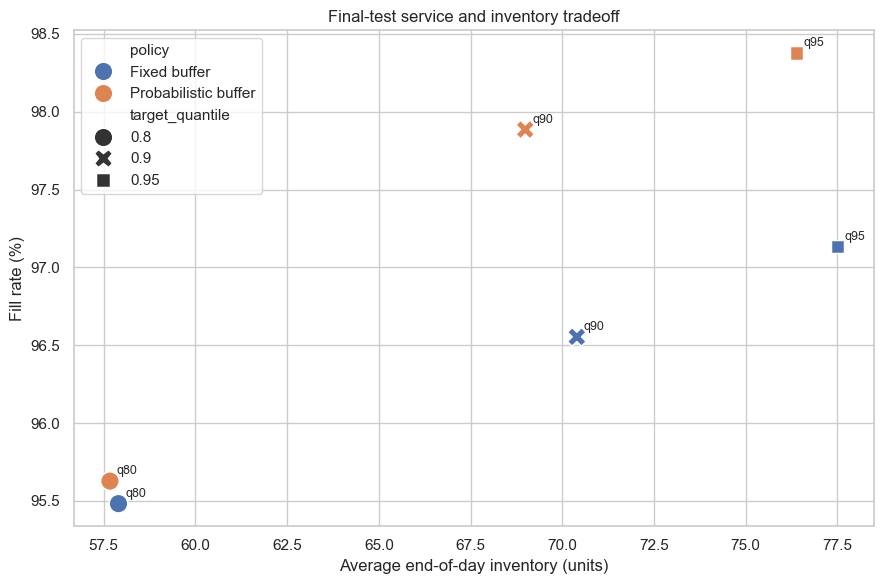

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(
    data=policy_metrics,
    x="average_ending_inventory",
    y="fill_rate_pct",
    hue="policy",
    style="target_quantile",
    s=180,
    ax=ax,
)
for row in policy_metrics.itertuples(index=False):
    ax.annotate(
        f"q{int(row.target_quantile * 100)}",
        (row.average_ending_inventory, row.fill_rate_pct),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9,
    )
ax.set(
    title="Final-test service and inventory tradeoff",
    xlabel="Average end-of-day inventory (units)",
    ylabel="Fill rate (%)",
)
plt.tight_layout()
fig.savefig(FIGURE_DIR / "service_inventory_tradeoff.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Paired bootstrap and sign-flip tests

Both policies face the same series and demand path, so policy differences are paired. The cluster bootstrap resamples complete series and preserves all 28 days. A 95% interval excluding zero is evidence that the selected-series average difference is stable in direction.

An exact sign-flip test is also reported for per-series differences. Its null hypothesis is that a policy difference is centered at zero across the selected series. Because the series were purposively selected, the result is evidence for this project sample rather than all M5 products.

In [9]:
series_policy_metrics = (
    simulation.groupby(["series_key", "target_quantile", "policy"], observed=True)
    .agg(
        demand=("actual_sales", "sum"),
        fulfilled=("fulfilled_units", "sum"),
        unmet_units=("unmet_units", "sum"),
        stockout_day_rate=("stockout_day", "mean"),
        average_ending_inventory=("ending_inventory", "mean"),
    )
    .reset_index()
)
series_policy_metrics["fill_rate"] = np.where(
    series_policy_metrics["demand"] > 0,
    series_policy_metrics["fulfilled"] / series_policy_metrics["demand"],
    np.nan,
)

comparison_rows = []
bootstrap_records = []
sign_patterns = np.asarray(list(product([-1, 1], repeat=len(series_order))))

for target in TARGET_QUANTILES:
    target_daily = simulation[simulation["target_quantile"] == target]

    bootstrap_differences = {
        "fill_rate_pct": [],
        "stockout_day_rate_pct": [],
        "unmet_units": [],
        "average_ending_inventory": [],
    }

    for _ in range(BOOTSTRAP_REPETITIONS):
        sampled_series = rng.choice(series_order, size=len(series_order), replace=True)
        sampled_parts = []
        for sample_id, series_key in enumerate(sampled_series):
            part = target_daily[target_daily["series_key"] == series_key].copy()
            part["bootstrap_cluster"] = sample_id
            sampled_parts.append(part)
        sample = pd.concat(sampled_parts, ignore_index=True)

        sample_metrics = sample.groupby("policy", observed=True).agg(
            demand=("actual_sales", "sum"),
            fulfilled=("fulfilled_units", "sum"),
            unmet_units=("unmet_units", "sum"),
            stockout_rate=("stockout_day", "mean"),
            average_inventory=("ending_inventory", "mean"),
        )
        bootstrap_differences["fill_rate_pct"].append(
            100
            * (
                sample_metrics.loc["Probabilistic buffer", "fulfilled"]
                / sample_metrics.loc["Probabilistic buffer", "demand"]
                - sample_metrics.loc["Fixed buffer", "fulfilled"]
                / sample_metrics.loc["Fixed buffer", "demand"]
            )
        )
        bootstrap_differences["stockout_day_rate_pct"].append(
            100
            * (
                sample_metrics.loc["Probabilistic buffer", "stockout_rate"]
                - sample_metrics.loc["Fixed buffer", "stockout_rate"]
            )
        )
        bootstrap_differences["unmet_units"].append(
            sample_metrics.loc["Probabilistic buffer", "unmet_units"]
            - sample_metrics.loc["Fixed buffer", "unmet_units"]
        )
        bootstrap_differences["average_ending_inventory"].append(
            sample_metrics.loc["Probabilistic buffer", "average_inventory"]
            - sample_metrics.loc["Fixed buffer", "average_inventory"]
        )

    target_metrics = policy_metrics[policy_metrics["target_quantile"] == target].set_index("policy")
    observed_differences = {
        "fill_rate_pct": (
            target_metrics.loc["Probabilistic buffer", "fill_rate_pct"]
            - target_metrics.loc["Fixed buffer", "fill_rate_pct"]
        ),
        "stockout_day_rate_pct": (
            target_metrics.loc["Probabilistic buffer", "stockout_day_rate_pct"]
            - target_metrics.loc["Fixed buffer", "stockout_day_rate_pct"]
        ),
        "unmet_units": (
            target_metrics.loc["Probabilistic buffer", "unmet_units"]
            - target_metrics.loc["Fixed buffer", "unmet_units"]
        ),
        "average_ending_inventory": (
            target_metrics.loc["Probabilistic buffer", "average_ending_inventory"]
            - target_metrics.loc["Fixed buffer", "average_ending_inventory"]
        ),
    }

    target_series = series_policy_metrics[series_policy_metrics["target_quantile"] == target]
    for metric, observed in observed_differences.items():
        values = np.asarray(bootstrap_differences[metric])
        p_value = np.nan
        if metric in ["unmet_units", "stockout_day_rate_pct", "average_ending_inventory"]:
            source_metric = "stockout_day_rate" if metric == "stockout_day_rate_pct" else metric
            wide = target_series.pivot(index="series_key", columns="policy", values=source_metric).reindex(series_order)
            paired_difference = (
                wide["Probabilistic buffer"] - wide["Fixed buffer"]
            ).to_numpy(dtype="float64")
            if metric == "stockout_day_rate_pct":
                paired_difference *= 100
            observed_series_mean = paired_difference.mean()
            null_means = (sign_patterns * paired_difference).mean(axis=1)
            p_value = (np.abs(null_means) >= abs(observed_series_mean)).mean()

        comparison_rows.append(
            {
                "target_quantile": target,
                "metric": metric,
                "difference_definition": "probabilistic_minus_fixed",
                "observed_difference": observed,
                "ci_lower": np.quantile(values, 0.025),
                "ci_upper": np.quantile(values, 0.975),
                "sign_flip_p_value": p_value,
            }
        )

policy_comparison = pd.DataFrame(comparison_rows)
display(policy_comparison.round(3))

,target_quantile,metric,difference_definition,observed_difference,ci_lower,ci_upper,sign_flip_p_value
0,0.80,fill_rate_pct,probabilistic_minus_fixed,0.145,-4.930,2.361,NaN
1,0.80,stockout_day_rate_pct,probabilistic_minus_fixed,1.488,-0.298,3.274,0.250
2,0.80,unmet_units,probabilistic_minus_fixed,-5.000,-109.000,71.000,1.000
3,0.80,average_ending_inventory,probabilistic_minus_fixed,-0.232,-11.110,16.631,0.989
4,0.90,fill_rate_pct,probabilistic_minus_fixed,1.332,-2.937,4.114,NaN
5,0.90,stockout_day_rate_pct,probabilistic_minus_fixed,0.595,-0.595,2.083,0.750
6,0.90,unmet_units,probabilistic_minus_fixed,-46.000,-180.000,37.000,0.875
7,0.90,average_ending_inventory,probabilistic_minus_fixed,-1.408,-18.268,19.698,0.917
8,0.95,fill_rate_pct,probabilistic_minus_fixed,1.245,-3.700,3.892,NaN
9,0.95,stockout_day_rate_pct,probabilistic_minus_fixed,0.595,-0.595,2.083,0.750


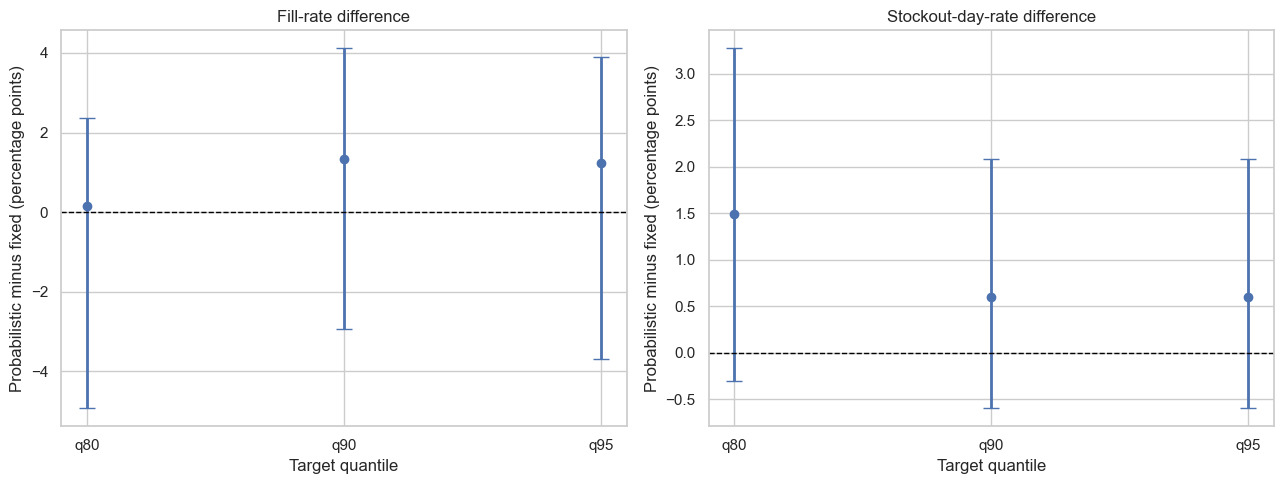

In [10]:
plot_comparison = policy_comparison[
    policy_comparison["metric"].isin(["fill_rate_pct", "stockout_day_rate_pct"])
].copy()
plot_comparison["metric"] = plot_comparison["metric"].map(
    {
        "fill_rate_pct": "Fill-rate difference",
        "stockout_day_rate_pct": "Stockout-day-rate difference",
    }
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=False)
for ax, metric in zip(axes, plot_comparison["metric"].unique()):
    subset = plot_comparison[plot_comparison["metric"] == metric]
    positions = np.arange(len(subset))
    estimates = subset["observed_difference"].to_numpy()
    errors = np.vstack(
        [estimates - subset["ci_lower"].to_numpy(), subset["ci_upper"].to_numpy() - estimates]
    )
    ax.errorbar(positions, estimates, yerr=errors, fmt="o", capsize=6, linewidth=2)
    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set(
        xticks=positions,
        xticklabels=[f"q{int(value * 100)}" for value in subset["target_quantile"]],
        title=metric,
        xlabel="Target quantile",
        ylabel="Probabilistic minus fixed (percentage points)",
    )

plt.tight_layout()
fig.savefig(FIGURE_DIR / "policy_difference_intervals.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Save final outputs

The daily table preserves the full audit trail. Summary tables contain the final policy metrics and paired statistical comparisons.

In [11]:
simulation_output = PROCESSED_DATA_DIR / "final_inventory_simulation_daily.csv"
review_output = PROCESSED_DATA_DIR / "final_inventory_review_orders.csv"
metrics_output = PROCESSED_DATA_DIR / "final_policy_metrics.csv"
comparison_output = PROCESSED_DATA_DIR / "final_policy_comparison_inference.csv"
profile_output = PROCESSED_DATA_DIR / "final_policy_metrics_by_profile.csv"

simulation.to_csv(simulation_output, index=False)
review_orders.to_csv(review_output, index=False)
policy_metrics.to_csv(metrics_output, index=False)
policy_comparison.to_csv(comparison_output, index=False)
profile_policy_metrics.to_csv(profile_output, index=False)

saved_outputs = pd.DataFrame(
    {
        "file": [
            simulation_output.name,
            review_output.name,
            metrics_output.name,
            comparison_output.name,
            profile_output.name,
        ],
        "rows": [
            len(simulation),
            len(review_orders),
            len(policy_metrics),
            len(policy_comparison),
            len(profile_policy_metrics),
        ],
    }
)
display(saved_outputs)

,file,rows
0,final_inventory_simulation_daily.csv,2016
1,final_inventory_review_orders.csv,288
2,final_policy_metrics.csv,6
3,final_policy_comparison_inference.csv,12
4,final_policy_metrics_by_profile.csv,24


## 9. Final interpretation

The final test gives a mixed, appropriately cautious answer to the research question.

At the 90th-percentile target, the probabilistic policy increases fill rate from 96.55% to 97.89%, reduces unmet units from 119 to 73, and lowers average ending inventory from 70.40 to 68.99 units. At the 95th percentile, fill rate rises from 97.13% to 98.38%, unmet units fall from 99 to 56, and average ending inventory falls from 77.51 to 76.40 units.

Those point estimates favor the probabilistic allocation at the higher targets. However, every 95% cluster-bootstrap interval for the policy differences includes zero. The final sample therefore provides suggestive evidence, not a statistically clear overall advantage.

The service measures also tell different stories. The probabilistic policy has fewer unmet units but slightly more stockout days. This means it avoids some large shortages while experiencing more small shortages. A policy cannot be called uniformly better without stating which service measure matters.

Profile results show that the benefit is not uniform. The probabilistic policy improves stable-series service and greatly reduces unnecessary intermittent-series inventory, but it performs worse for the variable group in this final period. This heterogeneity supports the project's original argument for series-specific uncertainty while also showing that empirical quantiles estimated from 51 training origins remain uncertain.

The conclusion applies only to the 12 selected series, the 28-day final period, and the stated periodic-review assumptions. These are simulated policy outcomes, not observed Walmart stockouts or inventory decisions.